In [1]:
import pandas as pd
import numpy as np
import copepodTCR as cpp
import seaborn as sn
from matplotlib import pyplot as plt

## plotting styles
plt.style.use('default')
color_basic = '#FFA500'
color_copepodTCR = '#015396'

## formula to calculate sensitivity and specificity based on the number of true-false positive-negatives
def calculate_tpr_fpr(tp, tn, fp, fn):

    tpr = tp / (tp + fn)
    fpr = fp / (fp + tn)

    return tpr, 1 - fpr

# Figure 2: Performance of copepodTCR’s interpretation framework on simulated data.

In [2]:
## DATA:  with fixed neg_share =0.3 or =0.6
table = pd.read_csv('./data/insilico-simulations.tsv', sep = '\t')
### control = 0 activated pools
control_ns = table[table['error'] == 100]
print(f'Simulations with fixed neg_shares: total {len(table)}, negative data {len(control_ns)}')
### with 0 erroneous non-activated pools
table_ns = table[table['error'] == 0]

Simulations with fixed neg_shares: total 9720, negative data 3240


## A
Sensitivity and specificity of the mixture model with parameters for the negative
distribution inferred from separate negative control data (separate control_negative) or from the pool with the lowest
activation signal (control_negative = lowest pool)

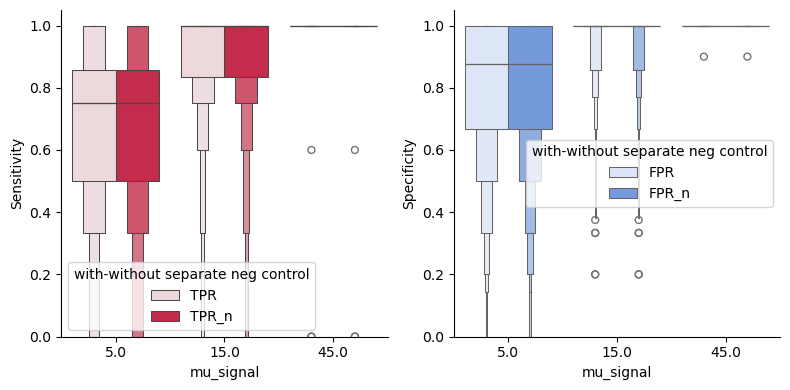

In [3]:
## simulations without negative control are indicated with by _n at the end of each metric
## simulations with negative control don't have this _n at the end of their metrics
fig, axes = plt.subplots(1, 2, figsize = (8, 4))

## sensitivity
ax = axes[0]
d1 = pd.melt(table_ns[['TPR', 'TPR_n', 'mu_signal']], id_vars=['mu_signal'],
             value_vars=['TPR', 'TPR_n'],
             var_name='with-without separate neg control',
             value_name='TPR_all')
sn.boxenplot(data = d1, y = 'TPR_all', x = 'mu_signal', hue = 'with-without separate neg control',
             ax = ax, palette = ['#F0D5DA', '#DC143C'])
ax.set_ylabel('Sensitivity')
ax.set_ylim(0, 1.05)

## specificity
ax = axes[1]
d1 = pd.melt(table_ns[['FPR', 'FPR_n', 'mu_signal']], id_vars=['mu_signal'],
             value_vars=['FPR', 'FPR_n'],
             var_name='with-without separate neg control',
             value_name='FPR_all')
sn.boxenplot(data = d1, y = 'FPR_all', x = 'mu_signal', hue = 'with-without separate neg control',
             ax = ax, palette = ['#D8E5FB', '#6495ED'])
ax.set_ylabel('Specificity')
ax.set_ylim(0, 1.05)

sn.despine()
plt.tight_layout()

## B
Sensitivity and specificity of the mixture model are similar across
simulations with different numbers of replicates per pool (1, 2, or 3 replicates)

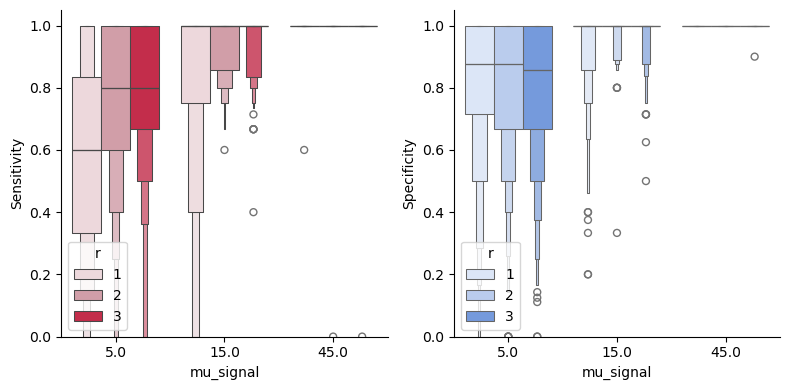

In [4]:
fig, axes = plt.subplots(1, 2, figsize = (8, 4))

## sensitivity
ax = axes[0]
sn.boxenplot(data = table_ns, y = 'TPR', x = 'mu_signal', hue = 'r', ax = ax, palette = ['#F0D5DA', '#DA95A3', '#DC143C'])
ax.set_ylabel('Sensitivity')
ax.set_ylim(0, 1.05)

## specificity
ax = axes[1]
sn.boxenplot(data = table_ns, y = 'FPR', x = 'mu_signal', hue = 'r', ax = ax, palette = ['#D8E5FB', '#B1CAF6', '#6495ED'])
ax.set_ylabel('Specificity')
ax.set_ylim(0, 1.05)

sn.despine()
plt.tight_layout()

## C
Percentage of simulations in which
all true cognate (no false positives) were assigned by the decision-tree algorithm to the “cognate” list, or in which all
cognate peptides were present in the “candidate” list. The black line on each bar shows the 95% confidence interval,
measured using bootstrapping with 1,000 samples.

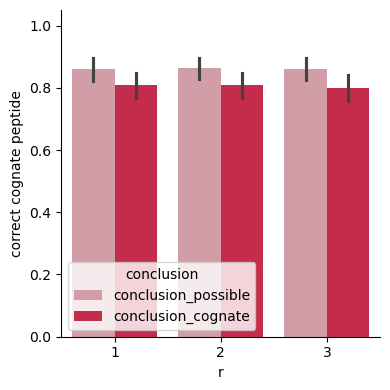

In [5]:
## conclusion_cognate == True => list with correct cognate peptides == (exactly equal!) list of cognate peptides predicted by the model
## conclusion_possible == True => correct cognate peptide is present in the list of peptide candidates

fig, axes = plt.subplots(1, 1, figsize = (4, 4))

plot_data = table_ns[table_ns['mu_signal'] == 45].melt(id_vars = 'r', value_vars = ['conclusion_cognate', 'conclusion_possible'], var_name = 'conclusion', value_name = 'proportion')

sn.barplot(data = plot_data, x = 'r', y = 'proportion', hue = 'conclusion',
    hue_order = ['conclusion_possible', 'conclusion_cognate'],
    palette={'conclusion_cognate': '#DC143C', 'conclusion_possible': '#DA95A3'}, ax=axes)

axes.set_ylim(0, 1.05)
axes.set_ylabel('correct cognate peptide')

sn.despine()
plt.tight_layout()